# Wyjaśnialność modeli: SHAP, PDP/ICE/ALE, case studies (waterfall, LIME), wierność i stabilność wyjaśnień

----
## 0. Importy

In [1]:
import sys, json, warnings; sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib, shap
from sklearn.base import clone
from sklearn.metrics import roc_auc_score
from lime.lime_tabular import LimeTabularExplainer
from src import config as cfg
from src.data import load_data, load_splits
from src.features import build_base_frame, CAT_COLS
from src.explain import (to_logodds, shap_lgbm, shap_logit, importance_table, rank_agreement, jaccard_topk,
                         quantile_grid, ice_curves, ale_1d, nonadditive_share, LimeAdapter, lime_weights,
                         pairwise_stability)
warnings.filterwarnings('ignore')
plt.style.use('default')

----
## 1. Modele i dane

In [2]:
df = load_data(); splits = load_splits(); y = df[cfg.TARGET]
tr, va, te = splits['train'], splits['valid'], splits['test']
L = joblib.load(cfg.ROOT / 'outputs/models/logit.joblib'); B = joblib.load(cfg.ROOT / 'outputs/models/lgbm_mono.joblib')
logit_model, F_LOG = L['model'], L['features']
bb_model, F_BB = B['model'], B['features']
base = build_base_frame(df)
X_log, X_bb = base[F_LOG], base[F_BB]
lo_log = lambda X: to_logodds(logit_model.predict_proba(X[F_LOG])[:, 1])      # predykcja w log-szansach
lo_bb = lambda X: to_logodds(bb_model.predict_proba(X[F_BB])[:, 1])
CATS_BB = [c for c in F_BB if c in CAT_COLS]
print('logit:', len(F_LOG), 'cech | black-box:', len(F_BB), 'cech')

logit: 9 cech | black-box: 31 cech


----
## 2. SHAP – ważność globalna

In [3]:
phi_bb, phi0_bb = shap_lgbm(bb_model, X_bb.loc[te])                  # TreeSHAP path-dependent
phi_log, phi0_log = shap_logit(logit_model, X_log.loc[te], X_log.loc[tr])  # φ = β(WoE − E[WoE]), tło = train
# kontrola addytywności (lokalna dokładność): φ0 + Σφ = log-szanse prognozy
print('max |φ0+Σφ − f(x)|  black-box:', np.abs(phi0_bb + phi_bb.sum(1) - lo_bb(X_bb.loc[te])).max().round(8),
      '| logit:', np.abs(phi0_log + phi_log.sum(1) - lo_log(X_log.loc[te])).max().round(8))
print(f'wartość bazowa φ0 (log-szanse): black-box {phi0_bb:.3f}, logit {phi0_log:.3f}')
imp = importance_table({'logit': phi_log, 'black-box': phi_bb})
imp.to_csv(cfg.TAB_DIR / '05_waznosc_shap.csv')
print('zgodność rankingów (średnie |SHAP|):', {k: round(v, 3) for k, v in rank_agreement(imp['logit'], imp['black-box']).items()})
imp.head(12).round(3)

max |φ0+Σφ − f(x)|  black-box: 0.0 | logit: 0.0
wartość bazowa φ0 (log-szanse): black-box -2.122, logit -2.180
zgodność rankingów (średnie |SHAP|): {'Spearman': np.float64(0.745), 'Jaccard top-5': 0.667}


,logit,black-box
wsk_struktury_kapitalu,0.234,0.235
wsk_stopa_zysku_sprzedaz,0.212,0.230
wsk_rotacja_wartosci_niewaterialnych,0.234,0.173
wsk_zysk_zobowiazania,0.213,0.162
wsk_poziom_kapitalu_obrotowego_netto,0.148,0.146
wsk_zadluzenia_krotkie,0.184,0.113
pkd_sekcja,0.000,0.086
wsk_zast_kapitalu_podstawowego,0.115,0.066
wsk_Zobowiazania_krotkoterminowe,0.000,0.059
wsk_struktury_finansowania,0.120,0.057


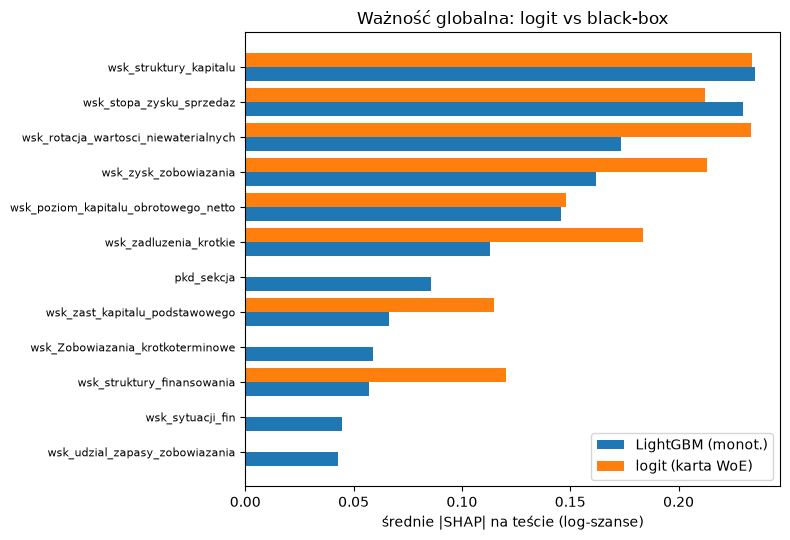

In [4]:
top12 = imp.head(12).index[::-1]
fig, ax = plt.subplots(figsize=(8, 5.5)); yy = np.arange(len(top12))
ax.barh(yy - 0.2, imp.loc[top12, 'black-box'], 0.4, label='LightGBM (monot.)')
ax.barh(yy + 0.2, imp.loc[top12, 'logit'], 0.4, label='logit (karta WoE)')
ax.set_yticks(yy); ax.set_yticklabels(top12, fontsize=8); ax.set_xlabel('średnie |SHAP| na teście (log-szanse)')
ax.legend(); ax.set_title('Ważność globalna: logit vs black-box'); plt.tight_layout()
plt.savefig(cfg.FIG_DIR / '05_waznosc_shap.png', dpi=150); plt.show()

**Wnioski:** black-box rozkłada wkład na więcej cech. Logit skupia ten sam sygnał w 9 cechach. Rankingi są zgodne (Spearman 0,75, Jaccard top-5 0,67).

----
## 3. Beeswarm

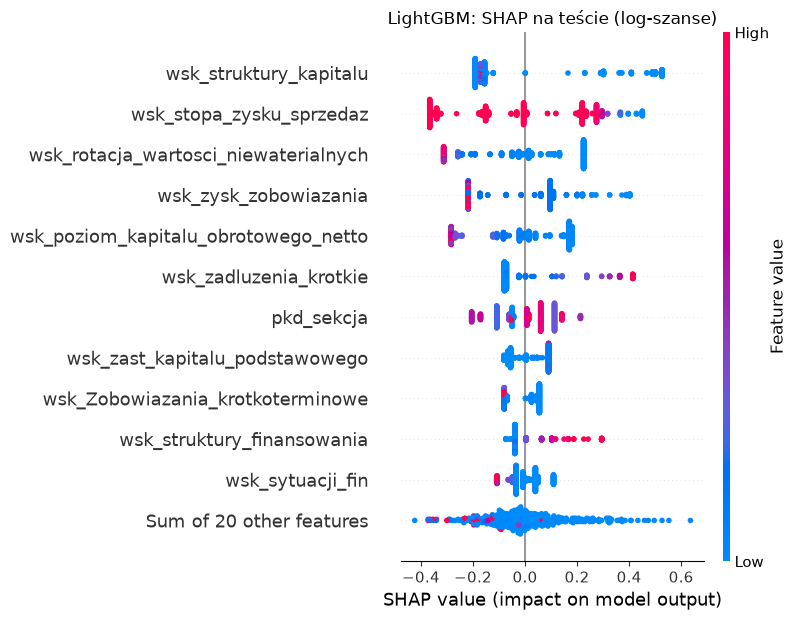

In [5]:
data_num = X_bb.loc[te].copy()
for c in CATS_BB:
    data_num[c] = data_num[c].astype('category').cat.codes
expl = shap.Explanation(values=phi_bb.values, base_values=np.full(len(te), phi0_bb),
                        data=data_num.values, feature_names=F_BB)
shap.plots.beeswarm(expl, max_display=12, show=False)
plt.title('LightGBM: SHAP na teście (log-szanse)'); plt.tight_layout()
plt.savefig(cfg.FIG_DIR / '05_beeswarm.png', dpi=150, bbox_inches='tight'); plt.show()

**Wnioski:** wykres pokazuje kierunek wpływu: kolor to wartość cechy, oś pozioma to wkład w ryzyko. Wysokie wartości rentowności i kapitału obniżają ryzyko, zgodnie z ograniczeniami monotonicznymi.

----
## 4. Zależności SHAP

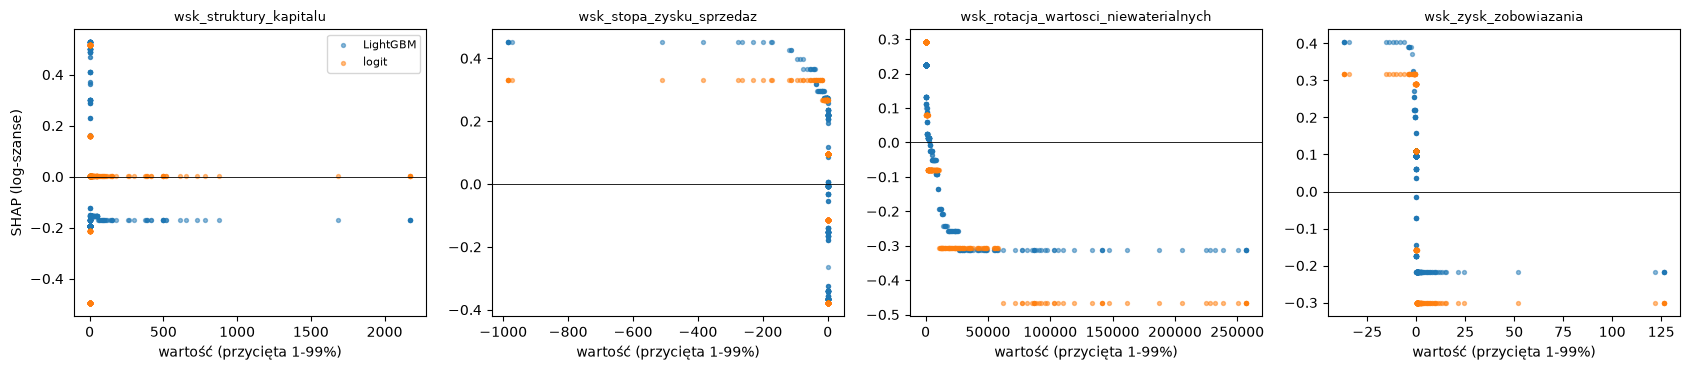

cechy: ['wsk_struktury_kapitalu', 'wsk_stopa_zysku_sprzedaz', 'wsk_rotacja_wartosci_niewaterialnych', 'wsk_zysk_zobowiazania']


In [6]:
TOP_NUM = [c for c in imp.index if c not in CAT_COLS][:4]
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, c in zip(axes, TOP_NUM):
    x = X_bb.loc[te, c]; lo_, hi_ = x.quantile([0.01, 0.99])
    ax.scatter(x.clip(lo_, hi_), phi_bb[c], s=8, alpha=0.5, label='LightGBM')
    if c in F_LOG:
        ax.scatter(x.clip(lo_, hi_), phi_log[c], s=8, alpha=0.5, label='logit')
    ax.axhline(0, c='k', lw=0.6); ax.set_title(c, fontsize=9); ax.set_xlabel('wartość (przycięta 1-99%)')
axes[0].set_ylabel('SHAP (log-szanse)'); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(cfg.FIG_DIR / '05_zaleznosci_shap.png', dpi=150); plt.show()
print('cechy:', TOP_NUM)

**Wnioski:** wkład SHAP zmienia się schodkowo dla obu modeli (przedziały WoE w logicie, progi drzew w LightGBM). Kształty dla wspólnych cech są podobne.

----
## 5. PDP i c-ICE

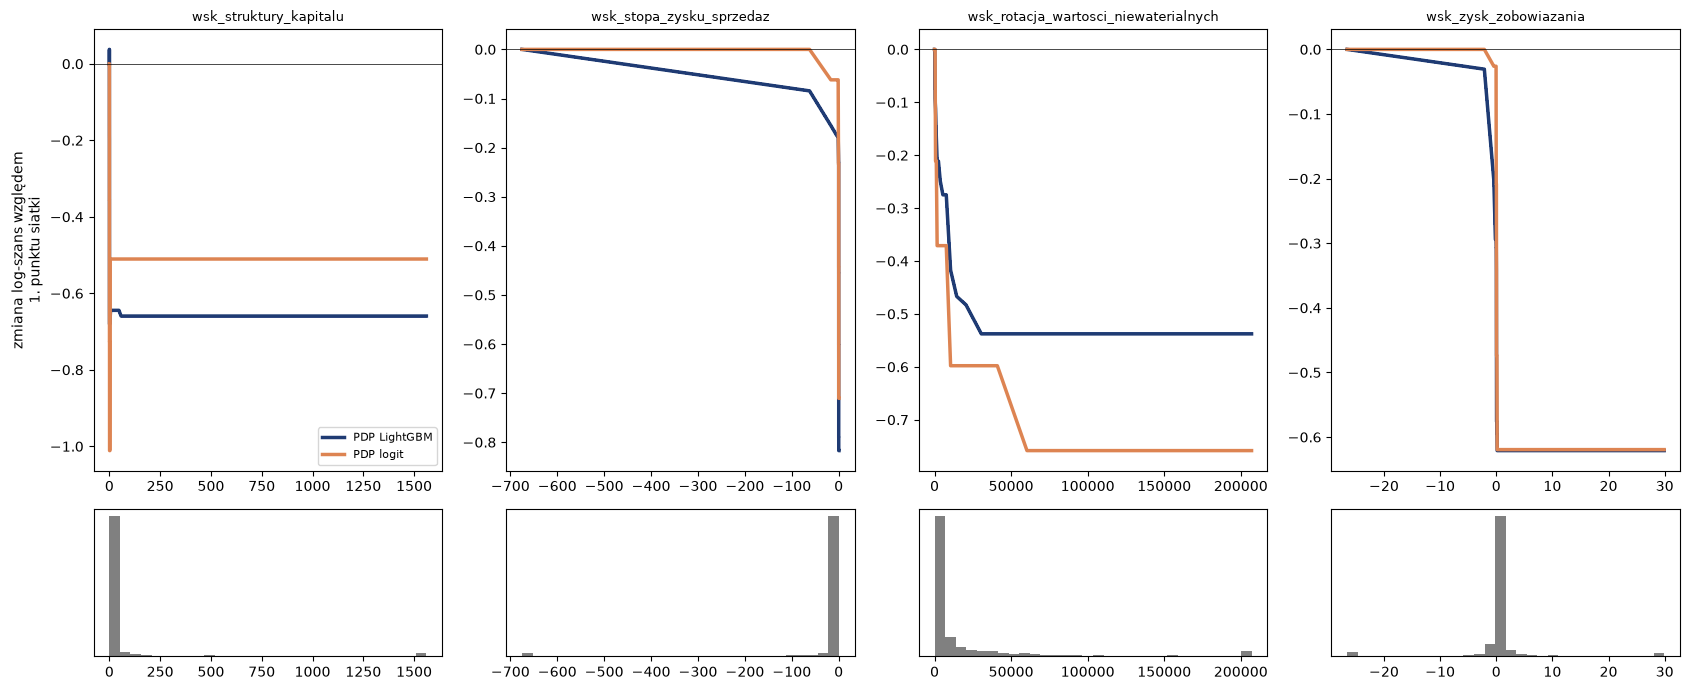

wsk_struktury_kapitalu: zmiana 10. pct = -0.659, 90. pct = -0.659
wsk_stopa_zysku_sprzedaz: zmiana 10. pct = -0.817, 90. pct = -0.817
wsk_rotacja_wartosci_niewaterialnych: zmiana 10. pct = -0.538, 90. pct = -0.538
wsk_zysk_zobowiazania: zmiana 10. pct = -0.621, 90. pct = -0.621


In [7]:
rng = np.random.default_rng(cfg.SEED)
X_te_all = base.loc[te, sorted(set(F_LOG) | set(F_BB))]
ice_idx = rng.choice(len(te), 150, replace=False)
fig, axes = plt.subplots(2, 4, figsize=(17, 7), gridspec_kw={'height_ratios': [3, 1]})
pdp_store = {}
for j, c in enumerate(TOP_NUM):
    grid = quantile_grid(base.loc[tr, c])
    ice_bb = ice_curves(lo_bb, X_te_all, c, grid)
    ax = axes[0, j]
    cice = ice_bb[ice_idx] - ice_bb[ice_idx, :1]
    ax.plot(grid, cice.T, c='#4C72B0', alpha=0.06)
    pdp_bb = ice_bb.mean(0); ax.plot(grid, pdp_bb - pdp_bb[0], c='#1f3b73', lw=2.5, label='PDP LightGBM')
    if c in F_LOG:
        pdp_log = ice_curves(lo_log, X_te_all, c, grid).mean(0)
        ax.plot(grid, pdp_log - pdp_log[0], c='#DD8452', lw=2.5, label='PDP logit')
    pdp_store[c] = (grid, pdp_bb)
    ax.set_title(c, fontsize=9); ax.axhline(0, c='k', lw=0.5)
    axes[1, j].hist(base.loc[tr, c].clip(grid[0], grid[-1]), bins=30, color='grey'); axes[1, j].set_yticks([])
axes[0, 0].set_ylabel('zmiana log-szans względem\n1. punktu siatki'); axes[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(cfg.FIG_DIR / '05_pdp_ice.png', dpi=150); plt.show()

for c in TOP_NUM:
    ice = ice_curves(lo_bb, X_te_all, c, pdp_store[c][0]); ch = ice[:, -1] - ice[:, 0]
    print(f'{c}: zmiana 10. pct = {np.percentile(ch, 10):+.3f}, 90. pct = {np.percentile(ch, 90):+.3f}')

Krzywe c-ICE są równoległe (ta sama zmiana dla 10. i 90. percentyla), czyli model nie ma interakcji – zgodnie z głębokością drzew 1. PDP dobrze opisuje więc każdą firmę.

----
## 6. ALE vs PDP

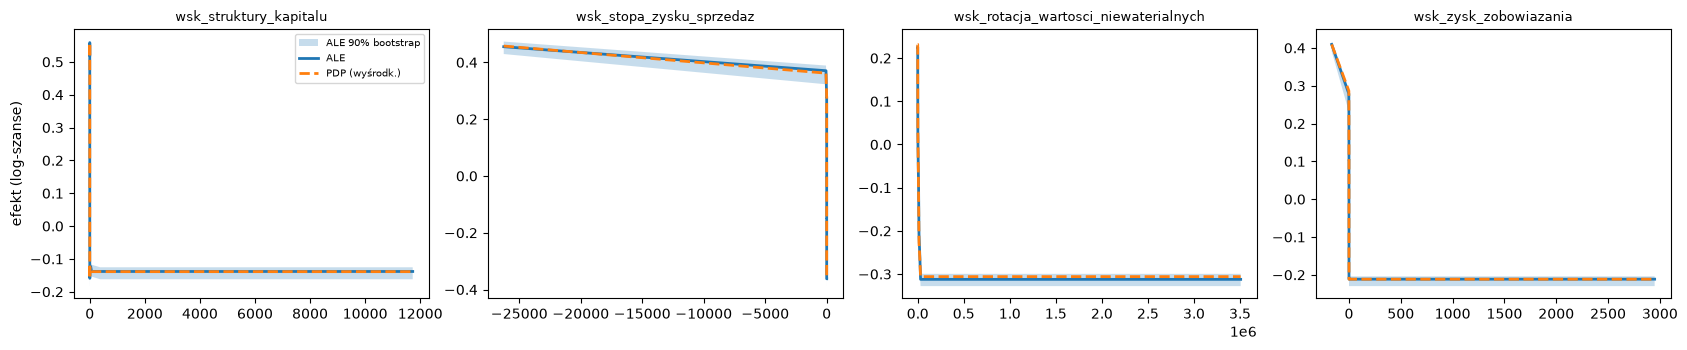

,max |ρ| z inną cechą,zakres ALE,max |PDP − ALE|,min. liczność przedziału,różnica / zakres
cecha,,,,,
wsk_struktury_kapitalu,0.822,0.718,0.018,22,0.026
wsk_stopa_zysku_sprzedaz,0.589,0.732,0.054,3,0.073
wsk_rotacja_wartosci_niewaterialnych,0.612,0.538,0.025,22,0.047
wsk_zysk_zobowiazania,0.589,0.490,0.024,7,0.049


In [8]:
corr = base.loc[tr, [c for c in F_BB if c not in CAT_COLS]].corr(method='spearman').abs()
corr = corr.mask(np.eye(len(corr), dtype=bool), 0)        # zerujemy przekątną
rows = []
fig, axes = plt.subplots(1, len(TOP_NUM), figsize=(17, 3.6))
for ax, c in zip(axes, TOP_NUM):
    edges, ale, nmin = ale_1d(lo_bb, X_te_all, c, K=20)
    boots = []
    for b in range(20):                                              # pasmo bootstrapowe (Lab 5)
        s = X_te_all.sample(frac=1, replace=True, random_state=b)
        e_b, a_b, _ = ale_1d(lo_bb, s, c, K=20); boots.append(np.interp(edges, e_b, a_b))
    lo_b, hi_b = np.percentile(boots, [5, 95], axis=0)
    grid, pdp = pdp_store[c]; pdp_i = np.interp(edges, grid, pdp); pdp_c = pdp_i - pdp_i.mean() + ale.mean()
    ax.fill_between(edges, lo_b, hi_b, alpha=0.25, label='ALE 90% bootstrap'); ax.plot(edges, ale, lw=2, label='ALE')
    ax.plot(edges, pdp_c, ls='--', lw=2, label='PDP (wyśrodk.)'); ax.set_title(c, fontsize=9)
    m = (edges >= grid[0]) & (edges <= grid[-1])
    rows.append({'cecha': c, 'max |ρ| z inną cechą': corr[c].max(), 'zakres ALE': np.ptp(ale[m]),
                 'max |PDP − ALE|': np.abs(pdp_c - ale)[m].max(), 'min. liczność przedziału': nmin})
axes[0].legend(fontsize=7); axes[0].set_ylabel('efekt (log-szanse)')
plt.tight_layout(); plt.savefig(cfg.FIG_DIR / '05_ale_pdp.png', dpi=150); plt.show()
ale_tab = pd.DataFrame(rows).set_index('cecha'); ale_tab['różnica / zakres'] = ale_tab['max |PDP − ALE|'] / ale_tab['zakres ALE']
ale_tab.round(3)

**Wnioski:** ALE i PDP różnią się najwyżej o 0,05 log-szans (3–7% zakresu efektu), także dla `wsk_struktury_kapitalu` (|ρ| 0,82 z inną cechą). Korelacje cech nie zniekształcają więc mocno PDP.

----
## 7. 2D PDP (interakcje)

wsk_struktury_kapitalu × wsk_stopa_zysku_sprzedaz: udział części nieaddytywnej 2D PDP = 0.0000 (black-box, max_depth = 1)


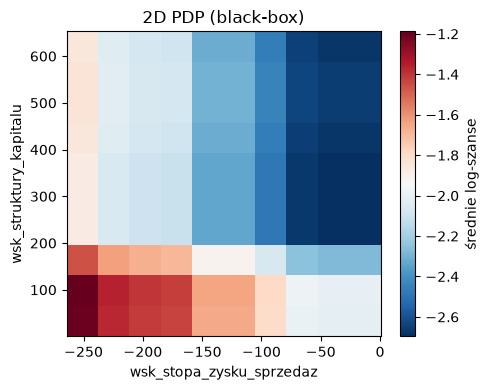

In [9]:
f1, f2 = TOP_NUM[:2]
P, g1, g2, share_bb = nonadditive_share(lo_bb, X_te_all, f1, f2)
print(f'{f1} × {f2}: udział części nieaddytywnej 2D PDP = {share_bb:.4f} (black-box, max_depth = 1)')
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(P, origin='lower', aspect='auto', cmap='RdBu_r',
               extent=[g2[0], g2[-1], g1[0], g1[-1]]); plt.colorbar(im, label='średnie log-szanse')
ax.set_xlabel(f2); ax.set_ylabel(f1); ax.set_title('2D PDP (black-box)'); plt.tight_layout()
plt.savefig(cfg.FIG_DIR / '05_pdp_2d.png', dpi=150); plt.show()

**Wnioski:** udział części nieaddytywnej = 0 – potwierdzenie, że model z drzewami głębokości 1 nie zawiera interakcji.

----
## 8. Ważność permutacyjna

In [10]:
auc0 = roc_auc_score(y.loc[te], bb_model.predict_proba(X_bb.loc[te])[:, 1])
perm = {}
for c in F_BB:
    drops = []
    for r in range(10):
        Xp = X_bb.loc[te].copy(); Xp[c] = Xp[c].sample(frac=1, random_state=r).values
        drops.append(auc0 - roc_auc_score(y.loc[te], bb_model.predict_proba(Xp)[:, 1]))
    perm[c] = np.mean(drops)
perm = pd.Series(perm, name='spadek AUC').sort_values(ascending=False)
print('zgodność permutacja vs SHAP:', {k: round(v, 3) for k, v in rank_agreement(perm.clip(lower=0), imp['black-box'].reindex(F_BB)).items()})
pd.DataFrame({'spadek AUC': perm, 'średnie |SHAP|': imp['black-box'].reindex(perm.index)}).head(10).round(4)

zgodność permutacja vs SHAP: {'Spearman': np.float64(0.603), 'Jaccard top-5': 0.429}


,spadek AUC,średnie |SHAP|
wsk_stopa_zysku_sprzedaz,0.0292,0.2298
wsk_struktury_kapitalu,0.0279,0.2351
wsk_zadluzenia_krotkie,0.0185,0.1128
wsk_poziom_kapitalu_obrotowego_netto,0.0086,0.1458
formaWlasnosci_Symbol,0.0053,0.0342
pkd_sekcja,0.0047,0.0859
wsk_zysk_zobowiazania,0.0046,0.1618
wsk_struktury_finansowania,0.0025,0.0571
wsk_zast_kapitalu_podstawowego,0.0020,0.0662
wsk_rent_kapitalu,0.0012,0.0426


**Wnioski:** ranking permutacyjny (spadek AUC po przemieszaniu cechy) jest umiarkowanie zgodny z SHAP (Spearman 0,60). W obu dwie najważniejsze cechy to `wsk_stopa_zysku_sprzedaz` i `wsk_struktury_kapitalu`.

----
## 9. Case studies

In [11]:
P_STAR = 0.10 / (0.10 + 0.45)
pv = pd.DataFrame({'PD black-box': bb_model.predict_proba(X_bb.loc[va])[:, 1],
                   'PD logit': logit_model.predict_proba(X_log.loc[va])[:, 1], 'default': y.loc[va].values}, index=va)
pv['różnica log-szans'] = to_logodds(pv['PD black-box']) - to_logodds(pv['PD logit'])
CASES = {'A: najwyższe PD': pv['PD black-box'].idxmax(),
         'B: graniczny (PD ≈ p*)': (pv['PD black-box'] - P_STAR).abs().idxmin(),
         'C: bezpieczny': pv['PD black-box'].idxmin(),
         'D: modele się różnią': pv['różnica log-szans'].abs().idxmax()}
cases = pv.loc[list(CASES.values())].assign(przypadek=list(CASES)).set_index('przypadek')
cases.insert(0, 'id', list(CASES.values())); cases.to_csv(cfg.TAB_DIR / '05_case_studies.csv')
cases.round(3)

,id,PD black-box,PD logit,default,różnica log-szans
przypadek,,,,,
A: najwyższe PD,2489,0.593,0.695,0,-0.448
B: graniczny (PD ≈ p*),12,0.183,0.250,1,-0.395
C: bezpieczny,1502,0.014,0.015,0,-0.039
D: modele się różnią,1049,0.079,0.033,0,0.935


**Wnioski:** wybraliśmy 4 firmy z valid: najwyższe PD, graniczną (PD ≈ p* = 18,2%), najbezpieczniejszą i taką, dla której modele najbardziej się różnią (PD 7,9% w LightGBM vs 3,3% w logicie).

----
## 10. Wkłady SHAP dla case studies

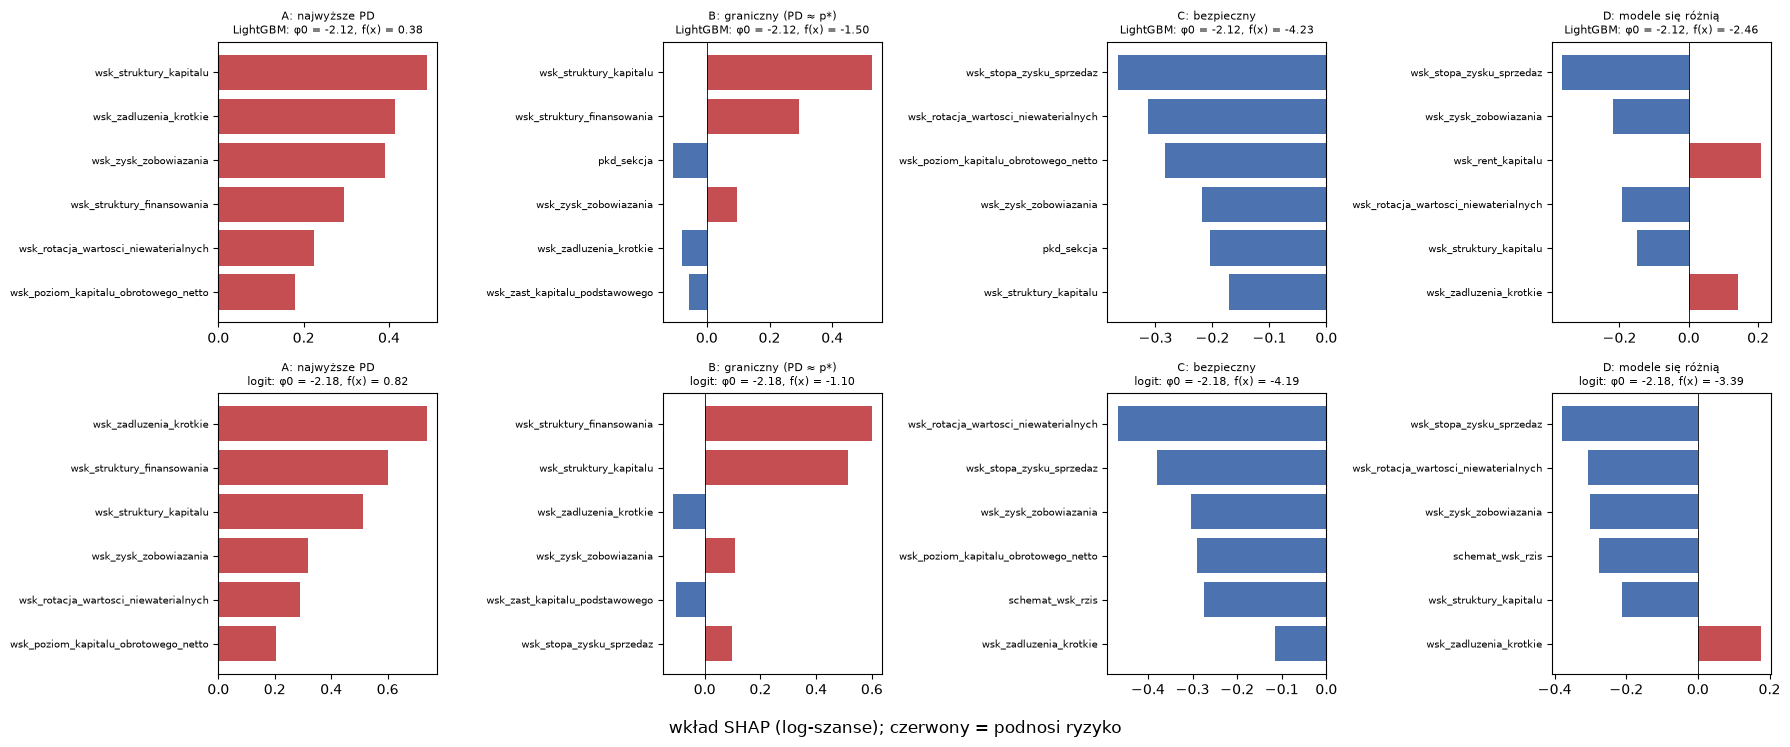

In [12]:
ids = list(CASES.values())
sh_bb, b0 = shap_lgbm(bb_model, X_bb.loc[ids]); sh_log, l0 = shap_logit(logit_model, X_log.loc[ids], X_log.loc[tr])
fig, axes = plt.subplots(2, 4, figsize=(18, 7.5))
for j, (name, i) in enumerate(CASES.items()):
    for r, (sh, base0, mdl) in enumerate([(sh_bb, b0, 'LightGBM'), (sh_log, l0, 'logit')]):
        s = sh.loc[i]; s = s.reindex(s.abs().sort_values().index[-6:])
        axes[r, j].barh(range(len(s)), s, color=['#C44E52' if v > 0 else '#4C72B0' for v in s])
        axes[r, j].set_yticks(range(len(s))); axes[r, j].set_yticklabels(s.index, fontsize=7)
        axes[r, j].axvline(0, c='k', lw=0.6)
        axes[r, j].set_title(f'{name}\n{mdl}: φ0 = {base0:.2f}, f(x) = {base0 + sh.loc[i].sum():.2f}', fontsize=8)
fig.supxlabel('wkład SHAP (log-szanse); czerwony = podnosi ryzyko')
plt.tight_layout(); plt.savefig(cfg.FIG_DIR / '05_case_studies_shap.png', dpi=150); plt.show()

----
## 11. Waterfall SHAP

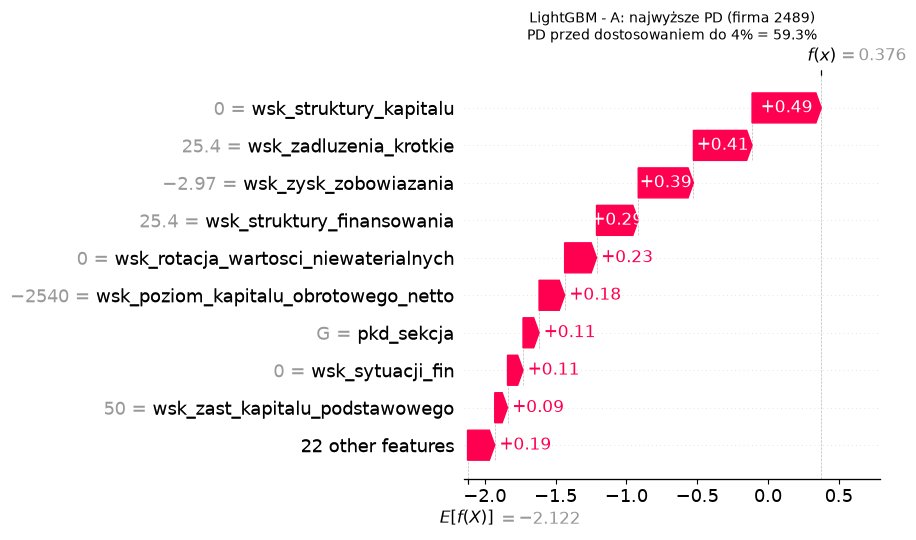

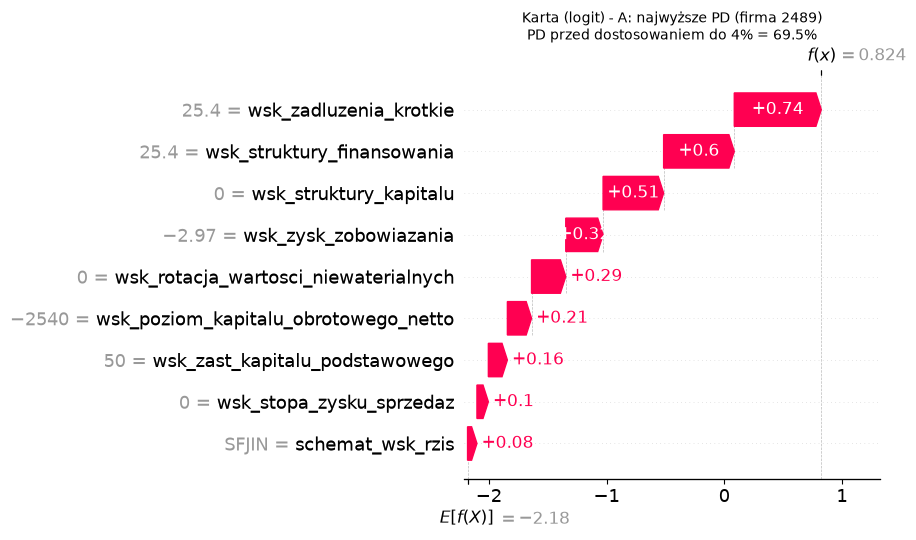

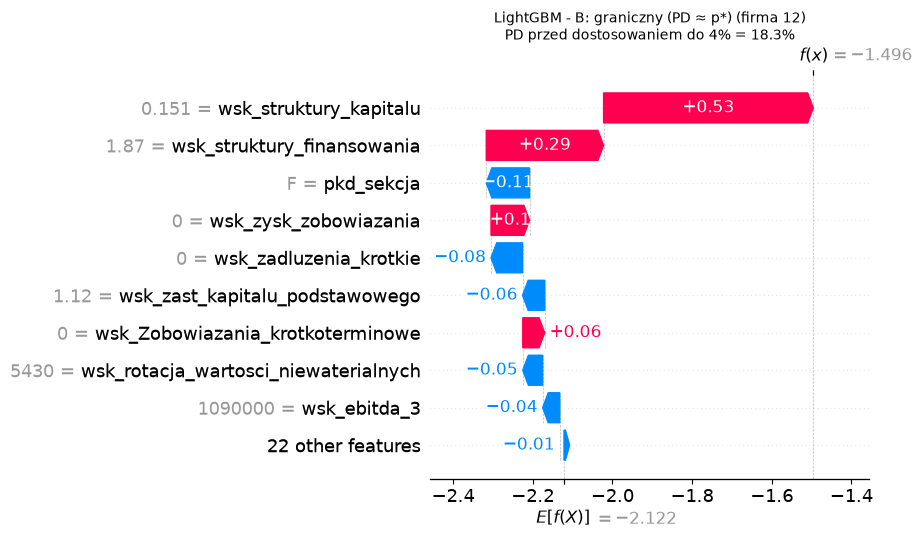

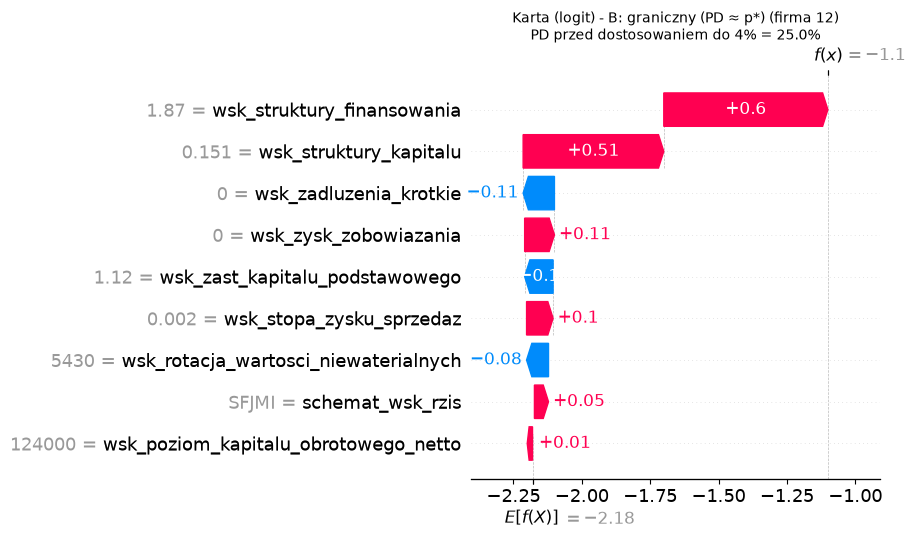

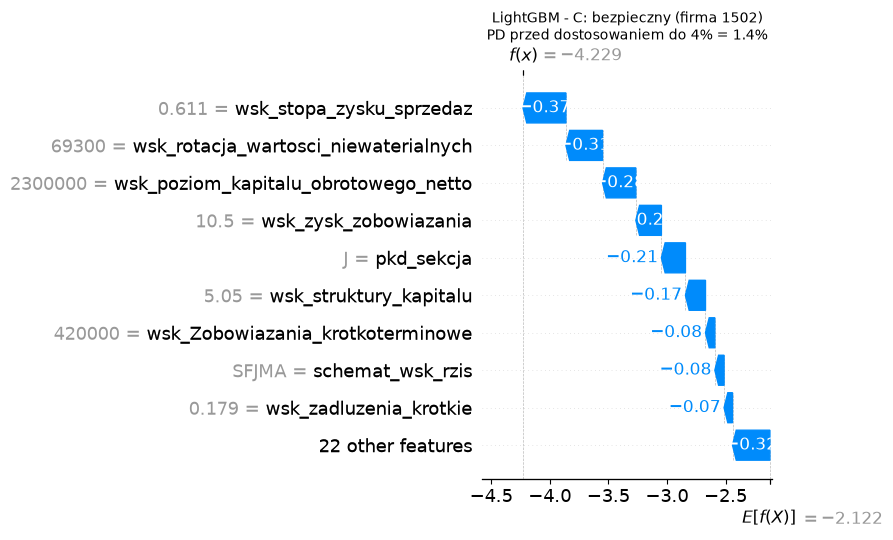

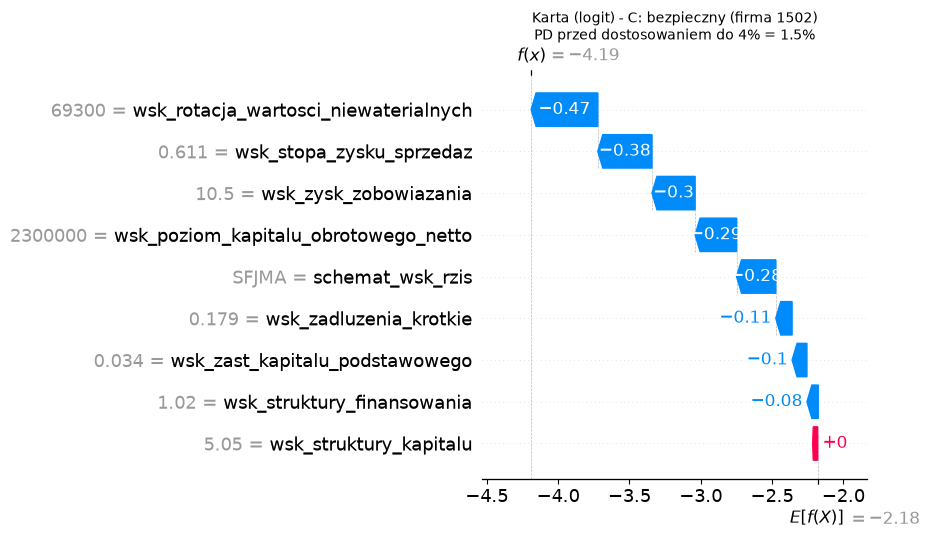

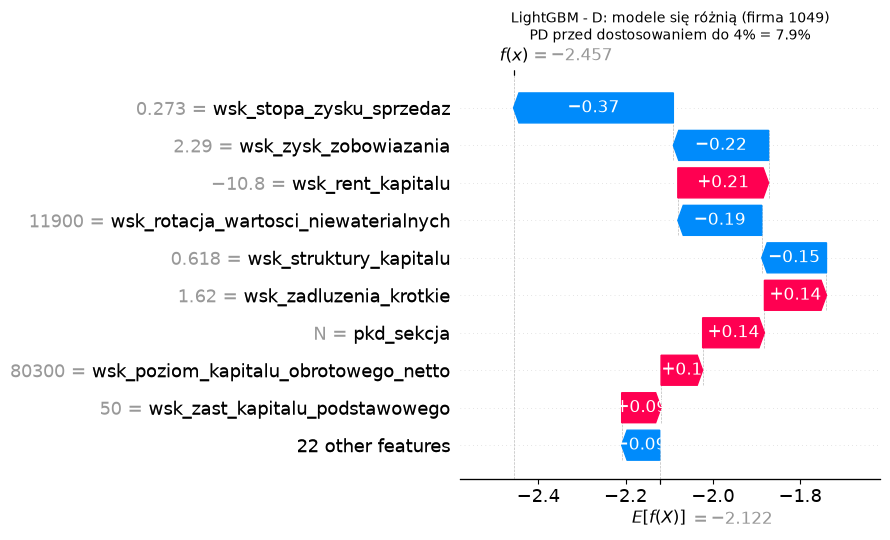

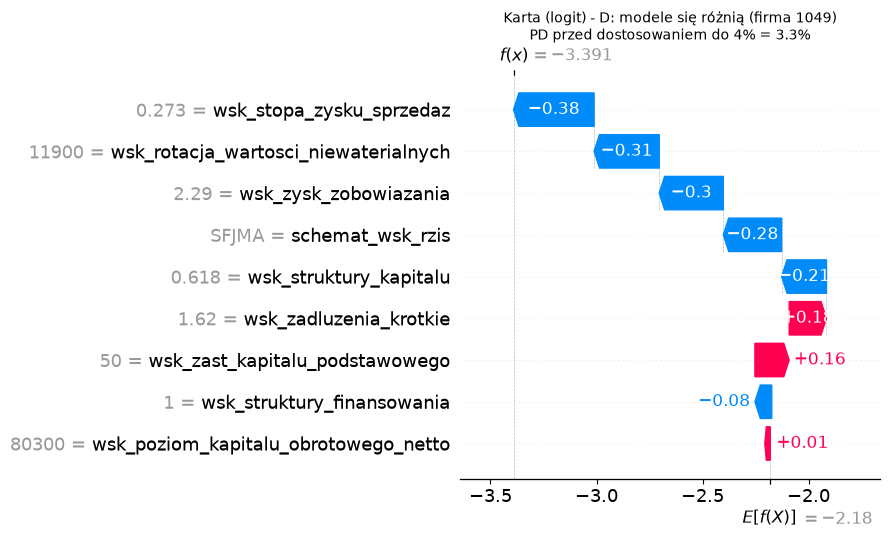

In [13]:

ids = list(CASES.values())
sh_bb, b0 = shap_lgbm(bb_model, X_bb.loc[ids])
sh_log, l0 = shap_logit(logit_model, X_log.loc[ids], X_log.loc[tr])
W_log = logit_model.named_steps['woe'].transform(X_log.loc[ids])

def waterfall(phi, base_value, data, title, fname, max_display=10):
    vals = data.copy()
    for c in vals.index:                                                   # czytelne wartości cech na osi
        v = vals[c]; vals[c] = v if isinstance(v, str) else ('brak' if pd.isna(v) else float(f'{v:.3g}'))
    expl = shap.Explanation(values=phi.values, base_values=base_value, data=vals.values, feature_names=list(phi.index))
    plt.figure()
    shap.plots.waterfall(expl, max_display=max_display, show=False)
    pdv = 1 / (1 + np.exp(-(base_value + phi.sum())))
    plt.title(f'{title}\nPD przed dostosowaniem do 4% = {pdv:.1%}', fontsize=10)
    plt.gcf().set_size_inches(9, 5.5); plt.tight_layout()
    plt.savefig(cfg.FIG_DIR / fname, dpi=150, bbox_inches='tight'); plt.show()

for k, (name, i) in enumerate(CASES.items(), 1):
    waterfall(sh_bb.loc[i], b0, X_bb.loc[i], f'LightGBM - {name} (firma {i})', f'05_waterfall_bb_{k}.png')
    waterfall(sh_log.loc[i], l0, X_log.loc[i], f'Karta (logit) - {name} (firma {i})', f'05_waterfall_logit_{k}.png')

----
## 12. Kody przyczyn

In [14]:
rows = []
for name, i in CASES.items():
    for mdl, sh, Xs in [('LightGBM', sh_bb, X_bb), ('logit', sh_log, X_log)]:
        s = sh.loc[i]; up = s[s > 0].sort_values(ascending=False).head(3)
        rows.append({'przypadek': name, 'model': mdl,
                     **{f'przyczyna {k+1}': f'{c} = {Xs.loc[i, c] if isinstance(Xs.loc[i, c], str) else round(float(Xs.loc[i, c]), 3)} (φ={v:+.2f})'
                        for k, (c, v) in enumerate(up.items())}})
reasons = pd.DataFrame(rows); reasons.to_csv(cfg.TAB_DIR / '05_kody_przyczyn.csv', index=False)
reasons

,przypadek,model,przyczyna 1,przyczyna 2,przyczyna 3
0,A: najwyższe PD,LightGBM,wsk_struktury_kapitalu = 0.0 (φ=+0.49),wsk_zadluzenia_krotkie = 25.42 (φ=+0.41),wsk_zysk_zobowiazania = -2.967 (φ=+0.39)
1,A: najwyższe PD,logit,wsk_zadluzenia_krotkie = 25.42 (φ=+0.74),wsk_struktury_finansowania = 25.42 (φ=+0.60),wsk_struktury_kapitalu = 0.0 (φ=+0.51)
2,B: graniczny (PD ≈ p*),LightGBM,wsk_struktury_kapitalu = 0.151 (φ=+0.53),wsk_struktury_finansowania = 1.869 (φ=+0.29),wsk_zysk_zobowiazania = 0.0 (φ=+0.10)
3,B: graniczny (PD ≈ p*),logit,wsk_struktury_finansowania = 1.869 (φ=+0.60),wsk_struktury_kapitalu = 0.151 (φ=+0.51),wsk_zysk_zobowiazania = 0.0 (φ=+0.11)
4,C: bezpieczny,LightGBM,wsk_efekt_dzwigni_fin_2 = 1.004 (φ=+0.03),wsk_zadluzenia_gotowki_1 = 0.036 (φ=+0.01),wsk_liczba_dni_istnienia = 2193.0 (φ=+0.01)
5,C: bezpieczny,logit,wsk_struktury_kapitalu = 5.051 (φ=+0.00),NaN,NaN
6,D: modele się różnią,LightGBM,wsk_rent_kapitalu = -10.797 (φ=+0.21),wsk_zadluzenia_krotkie = 1.617 (φ=+0.14),pkd_sekcja = N (φ=+0.14)
7,D: modele się różnią,logit,wsk_zadluzenia_krotkie = 1.617 (φ=+0.18),wsk_zast_kapitalu_podstawowego = 50.0 (φ=+0.16),wsk_poziom_kapitalu_obrotowego_netto = 80335.8...


----
## 13. ICE dla firmy granicznej

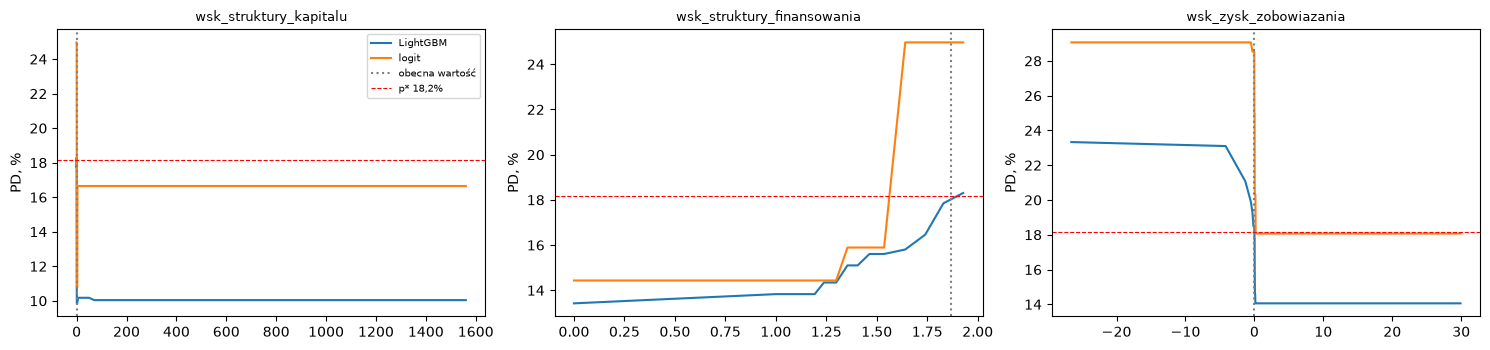

In [15]:
iB = CASES['B: graniczny (PD ≈ p*)']
top_up = [c for c in sh_bb.loc[iB].sort_values(ascending=False).index if c not in CAT_COLS][:3]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, c in zip(axes, top_up):
    grid = quantile_grid(base.loc[tr, c], 40)
    firm = base.loc[[iB], sorted(set(F_LOG) | set(F_BB))]
    pd_bb = 1 / (1 + np.exp(-ice_curves(lo_bb, firm, c, grid)[0]))
    ax.plot(grid, pd_bb * 100, label='LightGBM')
    if c in F_LOG:
        ax.plot(grid, 100 / (1 + np.exp(-ice_curves(lo_log, firm, c, grid)[0])), label='logit')
    ax.axvline(firm[c].iloc[0], c='grey', ls=':', label='obecna wartość'); ax.axhline(P_STAR * 100, c='r', ls='--', lw=0.8, label='p* 18,2%')
    ax.set_title(c, fontsize=9); ax.set_ylabel('PD, %')
axes[0].legend(fontsize=7); plt.tight_layout(); plt.savefig(cfg.FIG_DIR / '05_what_if.png', dpi=150); plt.show()

----
## 14. LIME

In [16]:
ad = LimeAdapter(X_bb.loc[tr], CATS_BB)
explainer = LimeTabularExplainer(ad.encode(X_bb.loc[tr]), feature_names=F_BB, categorical_features=ad.cat_idx,
                                 class_names=['dobry', 'zły'], mode='classification', random_state=cfg.SEED)
predict = ad.predict_fn(bb_model)
rows, lime_w = [], {}
for name, i in CASES.items():
    x = ad.encode(X_bb.loc[[i]])[0]
    exp = explainer.explain_instance(x, predict, num_features=8, num_samples=5000)
    w = lime_weights(exp, F_BB); lime_w[name] = w
    p_model = predict(x[None, :])[0, 1]
    rows.append({'przypadek': name, 'PD modelu': p_model, 'PD surogatu LIME': float(exp.local_pred[0]),
                 '|błąd aproksymacji|': abs(p_model - float(exp.local_pred[0])), 'lokalne R²': exp.score,
                 'Jaccard top-5 LIME vs SHAP': jaccard_topk(w.abs(), sh_bb.loc[i].abs(), 5),
                 'top-3 LIME': ', '.join(w.abs().nlargest(3).index)})
lime_tab = pd.DataFrame(rows).set_index('przypadek'); lime_tab.to_csv(cfg.TAB_DIR / '05_lime_case_studies.csv')
lime_tab.round(3)

,PD modelu,PD surogatu LIME,|błąd aproksymacji|,lokalne R²,Jaccard top-5 LIME vs SHAP,top-3 LIME
przypadek,,,,,,
A: najwyższe PD,0.593,0.442,0.151,0.578,1.000,"wsk_struktury_kapitalu, wsk_zysk_zobowiazania,..."
B: graniczny (PD ≈ p*),0.182,0.262,0.081,0.437,0.667,"wsk_struktury_kapitalu, wsk_zysk_zobowiazania,..."
C: bezpieczny,0.014,-0.077,0.092,0.312,0.667,"wsk_stopa_zysku_sprzedaz, wsk_zysk_zobowiazani..."
D: modele się różnią,0.079,0.142,0.063,0.347,0.429,"wsk_zadluzenia_krotkie, wsk_stopa_zysku_sprzed..."


----
## 15. Wierność LIME

In [17]:
sample_ids = pd.Index(va).to_series().sample(40, random_state=cfg.SEED)
fid = []
for i in sample_ids:
    x = ad.encode(X_bb.loc[[i]])[0]
    exp = explainer.explain_instance(x, predict, num_features=8, num_samples=5000)
    fid.append({'R²': exp.score, '|błąd|': abs(predict(x[None, :])[0, 1] - float(exp.local_pred[0]))})
fid = pd.DataFrame(fid); fid.to_csv(cfg.TAB_DIR / '05_lime_wiernosc.csv', index=False)
fid.describe(percentiles=[0.1, 0.5, 0.9]).round(3)

,R²,|błąd|
count,40.000,40.000
mean,0.337,0.053
std,0.137,0.040
min,0.134,0.001
10%,0.175,0.015
50%,0.308,0.051
90%,0.572,0.097
max,0.658,0.178


**Wnioski:** na 40 firmach mediana lokalnego R² wynosi 0,31, czyli LIME wyjaśnia ok. 30% zmienności modelu wokół firmy. To niska wierność – SHAP jest bardziej wiarygodny.

----
## 16. Stabilność LIME

In [18]:
x = ad.encode(X_bb.loc[[iB]])[0]
stab = {}
for ns in [1000, 5000]:
    ws = []
    for s in range(20):
        e = LimeTabularExplainer(ad.encode(X_bb.loc[tr]), feature_names=F_BB, categorical_features=ad.cat_idx,
                                 mode='classification', random_state=s)
        ws.append(lime_weights(e.explain_instance(x, predict, num_features=8, num_samples=ns), F_BB))
    stab[f'LIME, {ns} próbek'] = pairwise_stability(ws, k=5)
pd.DataFrame(stab).T.round(3)

,Jaccard top-5,Spearman wag
"LIME, 1000 próbek",0.831,0.918
"LIME, 5000 próbek",1.000,0.973


----
## 17. Stabilność SHAP między foldami

In [19]:
fold_imp_bb, fold_imp_log = [], []
for f in splits['folds']:
    m_bb = clone(bb_model).fit(X_bb.loc[f['train']], y.loc[f['train']])
    fold_imp_bb.append(shap_lgbm(m_bb, X_bb.loc[va])[0].abs().mean())
    m_log = clone(logit_model).fit(X_log.loc[f['train']], y.loc[f['train']])
    fold_imp_log.append(shap_logit(m_log, X_log.loc[va], X_log.loc[f['train']])[0].abs().mean())
stab['SHAP LightGBM, 5 foldów'] = pairwise_stability(fold_imp_bb, k=5)
stab['SHAP logit, 5 foldów'] = pairwise_stability(fold_imp_log, k=5)
stab_tab = pd.DataFrame(stab).T; stab_tab.to_csv(cfg.TAB_DIR / '05_stabilnosc.csv')
stab_tab.round(3)

,Jaccard top-5,Spearman wag
"LIME, 1000 próbek",0.831,0.918
"LIME, 5000 próbek",1.000,0.973
"SHAP LightGBM, 5 foldów",0.605,0.843
"SHAP logit, 5 foldów",0.767,0.642


**Wnioski:** po douczeniu na różnych foldach skład top-5 SHAP logitu jest stabilniejszy (Jaccard 0,77) niż LightGBM (0,60) – mniejszy model daje bardziej powtarzalne wyjaśnienia. Niższy Spearman logitu (0,64 vs 0,84) wynika z tego, że 9 cech ma zbliżone ważności, więc drobne zmiany zamieniają kolejność.